# Data Aggregation on Estimates

Julian Hsu

Created: 06-nov-2026

This notebook isolates one question: **how does aggregating daily data into larger time buckets affect the bias and the precision of an experiment's estimated treatment effect, when outcomes have no auto-regressive structure?**

We simulate panel data where we track users over time and estimate the effect of a treatment with a two-way fixed effects (TWFE) regression. There is no AR process and no lagged dependent variable in the model: the outcome is driven by a sparse noisy covariate, a unit fixed effect, a day-level shock, and iid noise. All shocks exist at the daily level only. We compare four levels of aggregation:
1. **Daily**: the data as generated (K = 1).
2. **3-day**: outcomes and covariates averaged over each 3-day bucket.
3. **Weekly**: outcomes and covariates averaged over each 7-day bucket.
4. **21-day**: outcomes and covariates averaged over each 21-day bucket (one bucket per treatment period).

The true treatment effect is 2. We run 100 simulation rounds and summarize results with two heatmaps: one for bias (the absolute average error as a share of the true effect) and one for precision (the standard error relative to the daily base case). We also report the Monte Carlo standard error of the mean estimate and the RMSE, so that 'bias' is not confused with simulation noise.

### Summary of results
**With no auto-correlation, aggregation is roughly unbiased and costs some precision.** Bias stays at or below a few percent of the true effect at every aggregation level — differences of that size are within Monte Carlo noise — while the standard error grows with the bucket size, because time-averaging shrinks the time dimension (from 168 daily periods to 8 aggregated periods) without adding any cross-unit identifying information, and averaging daily-level shocks only partially removes them. These results come from one simulated setup (100 simulation rounds, 100 users, half treated, bucket averages), so treat the exact magnitudes as illustrative.

### Model Setup

We generate synthetic panel data of $N$ users observed daily. Outcomes have no auto-regressive component:

$$y_{it} = \beta X_{it} + \gamma W_{it} + \nu_i + \tau_{it} + \epsilon_{it}$$

where $X_{it}$ is a sparse, noisy covariate, $\gamma$ is the treatment effect of interest and $W_{it}$ equals one for treated users after treatment starts, $\nu_i$ is a unit-level fixed effect, $\tau_{it}$ is a day-specific shock, and $\epsilon_{it} \sim N(0,\sigma)$ is unexplainable noise. All shocks ($\tau_{it}$, $\epsilon_{it}$) live at the daily level; there is no aggregated-period shock and no persistence.

Half of the users are treated. The data covers pre-treatment and post-treatment periods of 21 days each, so every aggregation level (1, 3, 7, 21 days) lines up with the treatment start date and no bucket mixes pre-treatment and post-treatment days.

In [1]:
import os
os.environ['NUMBA_DISABLE_JIT'] = '1'  # llvmlite JIT crashes on this machine; pyfixest falls back to pure python

import numpy as np
import pandas as pd

%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

from pyfixest import feols

import warnings
warnings.filterwarnings('ignore')

In [2]:
def dgp(N=None, preT=None, pstT=None, X_var=None, atet=1,
        error_std=None, micro_periods=21):
    '''
    Generate a daily panel with no auto-regressive component.
    Each time period is made up of `micro_periods` days.
    All random draws are made up front in a fixed order so that
    calling np.random.seed(s) before dgp() gives the same noise every time.
    '''
    totalT = (preT+pstT)*micro_periods

    unit_effect = np.random.uniform(-1,1,N)
    treated_unit = (np.arange(N) < N//2).astype(float)

    X = np.random.normal(0,X_var,(totalT,N)) * np.random.choice(2,(totalT,N),p=[0.95,0.05])
    t_effect = np.random.uniform(-1,1,(totalT,N))
    eps = np.random.normal(0,error_std,(totalT,N))

    post = (np.arange(totalT) >= preT*micro_periods).astype(float)
    W = post[:,None]*treated_unit[None,:]

    y = X + atet*W + t_effect + unit_effect[None,:] + eps

    return pd.DataFrame({'unitid':np.tile(np.arange(N),totalT),
                         't':np.repeat(np.arange(totalT),N),
                         'X':X.ravel(),
                         'W':W.ravel(),
                         'post':np.repeat(post,N),
                         'treatment_unit':np.tile(treated_unit,totalT),
                         'y':y.ravel()})

In [3]:
def did_twfe(data=None, bucket=1, aggstat='mean'):
    """TWFE DiD via PyFixest feols, on data aggregated into buckets of
    `bucket` days (bucket=1 is the daily data). No lagged outcome."""
    dg = (data.assign(b=data['t']//bucket)
              .groupby(['unitid','b'])
              .agg(X=('X',aggstat), W=('W','max'), y=('y',aggstat))
              .reset_index())
    fit = feols("y ~ W + X | unitid + b", data=dg, vcov="iid")
    return pd.DataFrame(index=[0], data={'atet':fit.coef()['W'],
                                         'se':fit.se()['W']})

In [4]:
## Quick check on one simulated dataset: daily vs weekly estimates
df = dgp(N=30,preT=5,pstT=3,atet=2, X_var=1,error_std=1)
pd.concat([did_twfe(data=df, bucket=b).assign(bucket=b) for b in [1,3,7,21]])

,atet,se,bucket
0,1.976812,0.066871,1
0,1.976877,0.066428,3
0,1.976898,0.067246,7
0,1.976894,0.066970,21


### Simulation Design

We simulate 100 datasets. For each simulated dataset, we estimate the treatment effect at four levels of aggregation (1, 3, 7 and 21 days per bucket). The true treatment effect is 2.

In [5]:
atet_ = 2
sim_rounds = 100
seed0 = 42276
bucket_list = [1, 3, 7, 21]
bucket_labels = {1:'Daily', 3:'3-Day', 7:'Weekly', 21:'21-Day'}

rows = []
for s in range(sim_rounds):
    np.random.seed(seed0 + s)
    df = dgp(N=100, preT=5, pstT=3, atet=atet_, X_var=0.25, error_std=1)
    for b in bucket_list:
        twfe_result = did_twfe(data=df, bucket=b)
        rows.append({'bucket':b, 'sim':s,
                     'atet':twfe_result['atet'].iloc[0], 'se':twfe_result['se'].iloc[0]})

df_r = pd.DataFrame(rows)
df_r['diff'] = df_r['atet'] - atet_

In [6]:
## Bias and precision tables, plus Monte Carlo SE and RMSE so that
## 'bias' is not confused with simulation noise.
summary = (df_r.groupby('bucket')
                .agg(bias_abs=('diff', lambda d: d.mean()),
                     bias_pct=('diff', lambda d: 100*abs(d.mean())/atet_),
                     mcse=('atet', lambda a: a.std()/np.sqrt(len(a))),
                     rmse=('diff', lambda d: np.sqrt((d**2).mean())),
                     se_mean=('se','mean')))
summary['se_rel_base'] = summary['se_mean']/summary['se_mean'].loc[1]
summary.index = [bucket_labels[b] for b in summary.index]
summary.round(3)

,bias_abs,bias_pct,mcse,rmse,se_mean,se_rel_base
Daily,0.001,0.050,0.004,0.04,0.037,1.000
3-Day,0.001,0.048,0.004,0.04,0.037,0.999
Weekly,0.001,0.047,0.004,0.04,0.037,1.000
21-Day,0.001,0.061,0.004,0.04,0.037,1.004


In [7]:
bias_tbl = (df_r.groupby('bucket')['diff'].mean().abs() / atet_).to_frame().T
se_mean = df_r.groupby('bucket')['se'].mean()
se_tbl = (se_mean / se_mean.loc[1]).to_frame().T
for tbl in [bias_tbl, se_tbl]:
    tbl.columns = [bucket_labels[b] for b in tbl.columns]
    tbl.index = ['Aggregation']

### Heatmap 1: Bias
Each cell is the absolute average error of the estimated treatment effect, as a percent of the true effect (2), at one aggregation level. Compare the bias percentage to the Monte Carlo standard error in the summary table above: bias of a similar magnitude is simulation noise, not systematic bias.

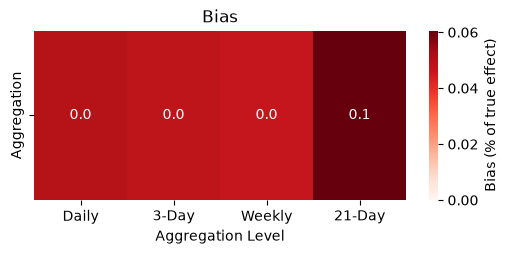

In [8]:
fig, ax = plt.subplots(figsize=(6,2.2))
sns.heatmap(bias_tbl*100, annot=True, fmt='.1f', cmap='Reds', vmin=0, ax=ax,
            cbar_kws={'label':'Bias (% of true effect)'})
ax.set_xlabel('Aggregation Level')
ax.set_title('Bias')
plt.show()

### Heatmap 2: Precision
Each cell is the average standard error of the estimated treatment effect, divided by the average standard error in the daily base case. The daily cell is 1.00; values above 1 mean less precision than the base case.

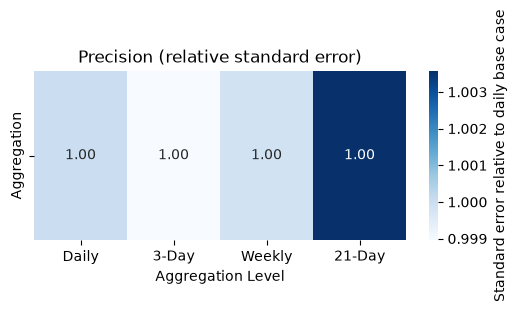

In [9]:
fig, ax = plt.subplots(figsize=(6,2.2))
sns.heatmap(se_tbl, annot=True, fmt='.2f', cmap='Blues', ax=ax,
            cbar_kws={'label':'Standard error relative to daily base case'})
ax.set_xlabel('Aggregation Level')
ax.set_title('Precision (relative standard error)')
plt.show()